**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 5**
Preprocesamiento de datos

---

*   NOMBRE: Italo Contreras
*   MATRÍCULA: A01841252

En esta actividad trabajarás con el archivo `heart_disease.csv`, basado en un conjunto de datos sobre pacientes y variables clínicas relacionadas con enfermedades cardíacas, disponible en Kaggle.

Los datos fueron recopilados para analizar la presencia de enfermedades cardíacas en los pacientes y contienen información demográfica, clínica y resultados de pruebas diagnósticas. Los indicadores incluidos son:

* `id`: Identificador único de cada paciente
* `age`: Edad del paciente en años
* `origin`: Lugar de estudio
* `sex`: Masculino / Femenino
* `cp`: Tipo de dolor torácico (angina típica, angina atípica, no anginal, asintomático)
* `trestbps`: Presión arterial en reposo (en mm Hg al ingreso al hospital)
* `chol`: Colesterol sérico en mg/dl
* `fbs`: Si el azúcar en ayunas > 120 mg/dl
* `restecg`: Resultados del electrocardiograma en reposo (normal, anomalía ST-T, hipertrofia ventricular izquierda)
* `thalach`: Frecuencia cardíaca máxima alcanzada
* `exang`: Angina inducida por ejercicio (Verdadero / Falso)
* `oldpeak`: Depresión del segmento ST inducida por ejercicio respecto al reposo
* `slope`: Pendiente del segmento ST en el pico de ejercicio
* `ca`: Número de vasos principales coloreados por fluoroscopía (0 - 3)
* `thal`: Resultado de la prueba de perfusión cardíaca (normal, defecto fijo, defecto reversible)
* `num`: Indica si el paciente tiene o no enfermedad cardíaca, o el grado de enfermedad (0 = sano, 1 - 4 = enfermedad) Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [353]:
# Importar las bibliotecas necesarias
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.impute import SimpleImputer

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 160)

## **Ejercicio 1**

**Descarga el archivo heart_disease.csv y guarda, en un dataframe (cardio_df), todos sus registros.**

In [354]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [355]:
cardio_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/MNA/1er trimestre/Ciencia y analitica de datos/semana 5/heart_disease.csv')

cardio_df.head(5)

,id,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


* **Haz que la columna `id` sea el índice del dataframe.**

In [356]:
cardio_df = cardio_df.set_index('id')

display(cardio_df.head())

,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
id,,,,,,,,,,,,,,,
1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


* **Utiliza el método info() del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?**

In [357]:
cardio_df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 918 entries, 1 to 920
Data columns (total 15 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   origin    918 non-null    object 
 3   cp        918 non-null    object 
 4   trestbps  859 non-null    float64
 5   chol      888 non-null    float64
 6   fbs       829 non-null    object 
 7   restecg   918 non-null    object 
 8   thalch    863 non-null    float64
 9   exang     863 non-null    object 
 10  oldpeak   856 non-null    float64
 11  slope     610 non-null    object 
 12  ca        309 non-null    float64
 13  thal      434 non-null    object 
 14  num       918 non-null    int64  
dtypes: float64(5), int64(2), object(8)
memory usage: 114.8+ KB


-7 columnas numéricas: `age`, `trestbps`, `chol`, `thalch`, `oldpeak`, `ca` y `num`.



-8 columnas de texto (object): `sex`, `origin`, `cp`, `fbs`, `restecg`, `exang`, `slope` y `thal`.

* **Determina la cantidad de valores únicos por columna.**

In [358]:
cardio_df.nunique().sort_values()

,0
sex,2
fbs,2
exang,2
restecg,3
slope,3
thal,3
cp,4
origin,4
ca,4
num,5


Ahi esta como se ve en la tabla claramente

## **Ejercicio 2**

**Examina las variables numéricas que presentan pocos valores únicos, ya que esto puede indicar que en realidad se tratan de variables categóricas codificadas como números.**

In [359]:
cardio_df.select_dtypes(include='number').nunique().sort_values()

,0
ca,4
num,5
age,50
oldpeak,53
trestbps,60
thalch,119
chol,216


* **Si existen casos de este tipo, conviértelas a categóricas. Antes de hacerlo, revisa sus descripciones para determinar si son ordinales o nominales y, si son ordinales, establece el orden correcto de las categorías.**

In [360]:
# ca y num son las numéricas con muy pocos valores únicos

cardio_df['ca'] = pd.Categorical(cardio_df['ca'], categories=[0.0, 1.0, 2.0, 3.0], ordered=True)

cardio_df['num'] = pd.Categorical(cardio_df['num'], categories=[0, 1, 2, 3, 4], ordered=True)


In [361]:

#las columnas de texto también se declaran como categorias como buena practica ya que tienen pocos valores como se vio arriba

# nominales (sin orden natural):

for c in ['sex', 'origin', 'cp', 'restecg', 'thal', 'fbs', 'exang']:
    cardio_df[c] = pd.Categorical(cardio_df[c])


# ordinal

cardio_df['slope'] = pd.Categorical(cardio_df['slope'],categories=['upsloping', 'flat', 'downsloping'], ordered=True)

cardio_df.dtypes

,0
age,int64
sex,category
origin,category
cp,category
trestbps,float64
chol,float64
fbs,category
restecg,category
thalch,float64
exang,category


---
## **Ejercicio 3**

**Obtén las estadísticas descriptivas de las variables, realizando el análisis por separado para las variables numéricas y las categóricas**

In [362]:
num_cols = cardio_df.select_dtypes(include='number').columns
cat_cols = cardio_df.select_dtypes(include='category').columns


* **Para las numéricas, incluye el sesgo y la curtosis.**

In [363]:
desc_num = cardio_df[num_cols].describe().T
desc_num['sesgo'] = cardio_df[num_cols].skew()
desc_num['curtosis'] = cardio_df[num_cols].kurt()

desc_num.round(2)

,count,mean,std,min,25%,50%,75%,max,sesgo,curtosis
age,918.0,53.53,9.41,28.0,47.0,54.0,60.0,77.0,-0.19,-0.38
trestbps,859.0,132.29,18.54,80.0,120.0,130.0,140.0,200.0,0.63,0.63
chol,888.0,242.19,53.42,85.0,216.0,223.0,268.0,603.0,1.64,6.57
thalch,863.0,137.53,25.95,60.0,120.0,140.0,157.0,202.0,-0.21,-0.48
oldpeak,856.0,0.88,1.09,-2.6,0.0,0.5,1.5,6.2,1.04,1.12


`oldpeak` (+1.04) y `trestbps` (+0.63) tiene cola a la derecha revisando el sesgo. `age` (-0.19) y `thalch` (-0.21) son casi simétricas

* **Para las categóricas, imprime además las tablas de frecuencia.**

In [364]:
display(cardio_df[cat_cols].describe().T)

for c in cat_cols:
    print('---', c, '---')
    display(cardio_df[c].value_counts(dropna=False))

,count,unique,top,freq
sex,918,2,Male,724
origin,918,4,Cleveland,304
cp,918,4,asymptomatic,495
fbs,829,2,False,691
restecg,918,3,normal,551
exang,863,2,False,526
slope,610,3,flat,345
ca,309.0,4.0,0.0,181.0
thal,434,3,normal,196
num,918,5,0,411


--- sex ---


,count
sex,
Male,724
Female,194


--- origin ---


,count
origin,
Cleveland,304
Hungary,292
VA Long Beach,200
Switzerland,122


...

,count
ca,
NaN,609
0.0,181
1.0,67
2.0,41
3.0,20


--- thal ---


,count
thal,
NaN,484
normal,196
reversable defect,192
fixed defect,46


--- num ---


,count
num,
0,411
1,263
2,109
3,107
4,28


---
## **Ejercicio 4**

**Calcula el porcentaje de valores faltantes en cada columna**

In [365]:
pct_faltantes = (cardio_df.isna().mean() * 100).sort_values(ascending=False)

pct_faltantes.round(2)

,0
ca,66.34
thal,52.72
slope,33.55
fbs,9.69
oldpeak,6.75
trestbps,6.43
thalch,5.99
exang,5.99
chol,3.27
sex,0.00


* **Elimina aquellas columnas cuyo porcentaje de valores faltantes supere el 30%.**

In [366]:
cols_eliminar = pct_faltantes[pct_faltantes > 30].index.tolist()
cardio_df = cardio_df.drop(columns=cols_eliminar)

cardio_df.head(5)

,age,sex,origin,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,num
id,,,,,,,,,,,,
1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,0
2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,2
3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,1
4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,0
5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,0


Se eliminaron las columnas: `ca`, `thal` y `slope`

* **Crea un mapa de calor que visualice la distribución de los valores faltantes en todas las columnas restantes.**

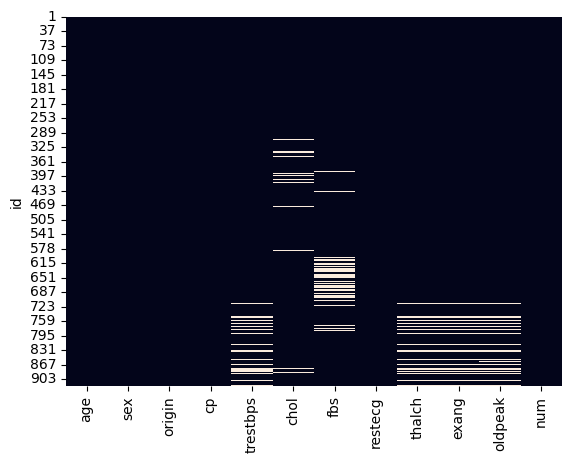

In [367]:
sns.heatmap(cardio_df.isna(), cbar=False)
plt.show()

* **Algunas variables presentan valores faltantes de manera simultánea; es decir, en el mapa se pueden identificar filas donde varias están ausentes al mismo tiempo. Enumera cuáles son dichas variables e investiga si esta concurrencia tiene sentido desde un punto de vista médico o clínico.**

In [368]:
cols_mv = cardio_df.columns[cardio_df.isna().any()]

print('Correlación entre los indicadores de faltantes')
display(cardio_df[cols_mv].isna().corr().round(2))


Correlación entre los indicadores de faltantes


,trestbps,chol,fbs,thalch,exang,oldpeak
trestbps,1.00,0.03,-0.07,0.96,0.96,0.90
chol,0.03,1.00,-0.06,0.03,0.03,0.02
fbs,-0.07,-0.06,1.00,-0.08,-0.08,-0.03
thalch,0.96,0.03,-0.08,1.00,1.00,0.92
exang,0.96,0.03,-0.08,1.00,1.00,0.92
oldpeak,0.90,0.02,-0.03,0.92,0.92,1.00


In [369]:
print('Faltantes de thalch por lugar de estudio')
display(pd.crosstab(cardio_df.thalch.isna(), cardio_df.origin))

Faltantes de thalch por lugar de estudio


origin,Cleveland,Hungary,Switzerland,VA Long Beach
thalch,,,,
False,304,291,121,147
True,0,1,1,53


Variables que faltan de manera simultanea: `trestbps`, `thalch`, `exang` y `oldpeak`, vemos que la correlacion entre ellos es altisima, desde 0.92 hasta 1

Si tienen sentido ya que todos son el resultado de que si una prueba de esfuerzo no sale bien entonces estas 4 mediciones van a faltar

Lo confirma el origen: 53 de los 55 faltantes de thalch son del centro VA Long Beach

---
## **Ejercicio 5**

**Si centramos el análisis en una de las variables identificadas en el ejercicio anterior, se puede suponer que los hallazgos obtenidos podrían ser aplicables a las demás variables que presentan un patrón similar.**


In [370]:
#se puede reutilizar las funciones como se menciona en las instsrucciones


from scipy.stats import ttest_ind

def Diagnose_MV_Numerical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    labels=[]
    box_sr = pd.Series('',index = BM_MV.unique())
    for poss in BM_MV.unique():
        BM = BM_MV == poss
        box_sr[poss] = df[BM][str_att_name].dropna()
        labels.append(MV_labels[poss])

    plt.boxplot(box_sr,vert=False)
    plt.yticks([1,2],labels)
    plt.xlabel(str_att_name)
    plt.show()

    plt.figure(figsize=(10,4))

    att_range = (df[str_att_name].min(),df[str_att_name].max())

    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].hist()
        plt.xlim = att_range
        plt.xlabel(str_att_name)
        plt.title(MV_labels[poss])

    plt.show()

    group_1_data = df[BM_MV][str_att_name].dropna()
    group_2_data = df[~BM_MV][str_att_name].dropna()

    p_value = ttest_ind(group_1_data,group_2_data).pvalue

    print('p-value of t-test: {}'.format(p_value))

In [371]:
from scipy.stats import chi2_contingency
def Diagnose_MV_Categorical(df,str_att_name,BM_MV):
    MV_labels = {True:'With Missing Values',False:'Without Missing Values'}

    plt.figure(figsize=(10,4))
    for i,poss in enumerate(BM_MV.unique()):
        plt.subplot(1,2,i+1)
        BM = BM_MV == poss
        df[BM][str_att_name].value_counts().plot.bar()
        plt.title(MV_labels[poss])
    plt.show()

    contigency_table = pd.crosstab(BM_MV,df[str_att_name])
    p_value = chi2_contingency(contigency_table)[1]

    print('p-value of Chi_squared test: {}'.format(p_value))

* **¿Tendrán los valores faltantes de `thalch` relación con alguna otra variable?**

  **Para ello deberás dividir cada columna en dos grupos: con / sin faltantes en `thalch` y utilizar métodos gráficos y pruebas de hipótesis para ver si hay diferencias significativas.**

In [372]:
#vemos los con/sin faltantes thalch
BM_MV = cardio_df.thalch.isna()

print(BM_MV.value_counts())

thalch
False    863
True      55
Name: count, dtype: int64


  * **Numéricas: `age`, `chol`**

Graficas para  age


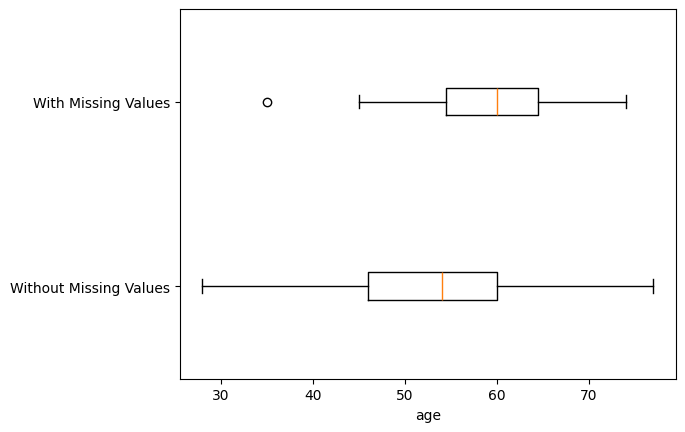

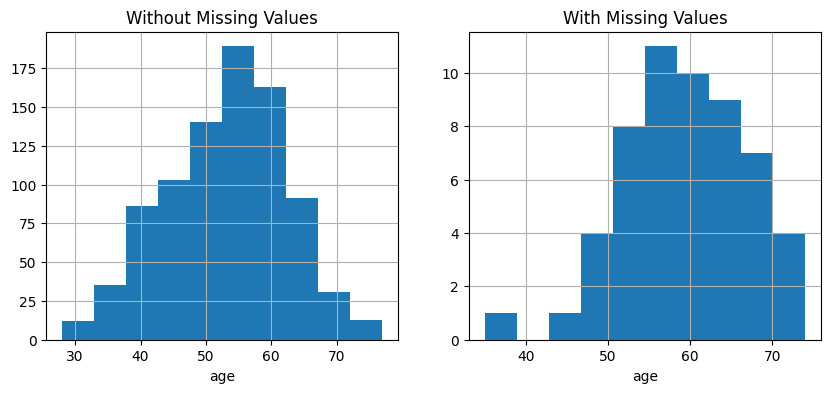

p-value of t-test: 1.5041244185890902e-06
 
Graficas para  chol


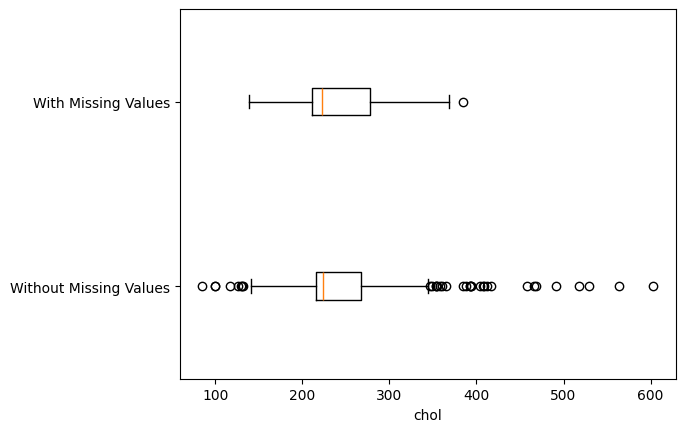

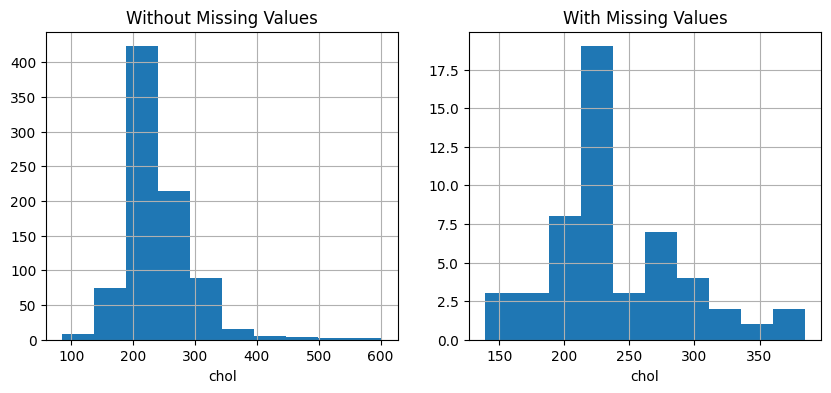

p-value of t-test: 0.7165289974295672
 


In [373]:
numerical_attributes = ['age', 'chol']

for att in numerical_attributes:
    print('Graficas para ',att)
    Diagnose_MV_Numerical(cardio_df, att, BM_MV)
    print(" ")

  * **Categóricas: `restecg`, `cp`**

Graficas para  restecg


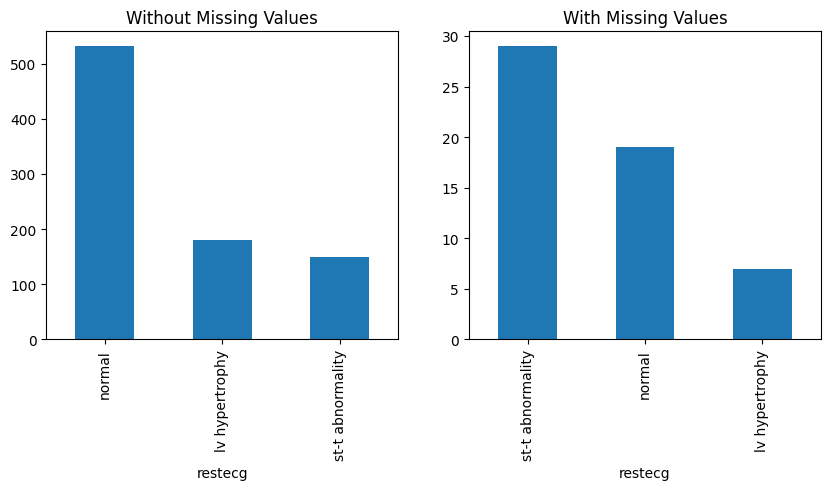

p-value of Chi_squared test: 1.1472889573985467e-09
 
Graficas para  cp


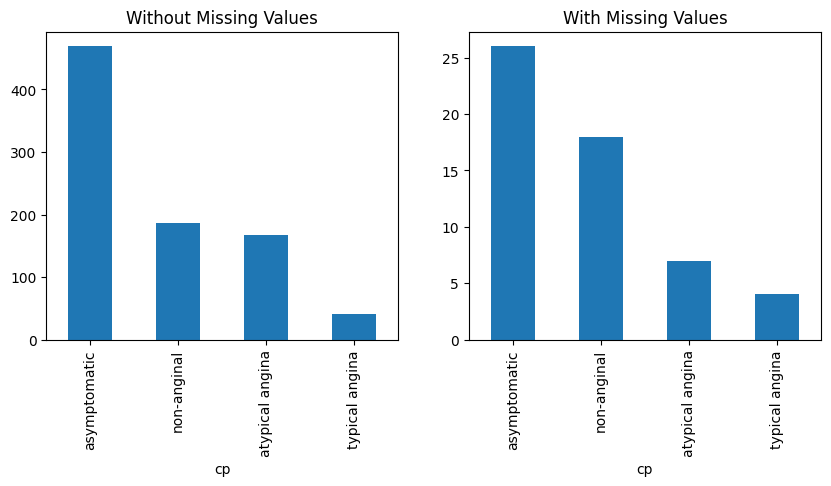

p-value of Chi_squared test: 0.15420097177251701
 


In [374]:
categorical_attributes = ['restecg', 'cp']

for att in categorical_attributes:
    print('Graficas para ',att)
    Diagnose_MV_Categorical(cardio_df, att, BM_MV)
    print(" ")

* **Incluye las conclusiones del análisis con los resultados obtenidos.**

Con α = 0.05:

| Variable | Prueba | p-value | ¿Diferencia significativa? |
|---|---|---|---|
| age | t-test | 1.5 × 10⁻⁶ | Sí |
| chol | t-test | 0.7165 | No |
| restecg | Chi-cuadrado | 1.1 × 10⁻⁹ | Sí |
| cp | Chi-cuadrado | 0.1542 | No |

`age` y `restecg` sí se relacionan con la ausencia de `thalch`. `chol` y `cp` no muestran diferencias.

* **Justifica si el mecanismo de faltantes de `thalch` es MCAR (*Missing Completely at Random*) o MAR (*Missing at Random*).**


La falta de thalc se puede predecir a partir de age y restecg (como vimos por el p-value de t-test y Chi-cuadrado) entonces es MAR, si no se pudiera predecir o fuera independiente de todas las variables seria MCAR

---
## **Ejercicio 6**



**La imputación de una variable con valores faltantes puede realizarse por grupos o segmentos relevantes. Esto significa que, en lugar de utilizar una estadística global de toda la columna, se calcula la estadística correspondiente dentro de cada grupo definido por otra variable, haciendo:**

> `df['var_with_missing'] = df.groupby('related_var')['var_with_missing'].transform(lambda x: x.fillna(x.median()))`



* **Utiliza la variable `restecg` para separar los grupos e imputar `thalch` y todas las variables con patrón de faltantes similar (identificadas en el ejercicio 4). Asegúrate de cambiar la función de agregado si hay variables no numéricas.**

In [375]:
vars_num_patron = ['trestbps', 'thalch', 'oldpeak']   # al ser numéricas usamos la mediana
vars_cat_patron = ['exang']                           # al ser categórica usamos la moda

for v in vars_num_patron:
    cardio_df[v] = cardio_df.groupby('restecg', observed=True)[v].transform(
        lambda x: x.fillna(x.median()))

for v in vars_cat_patron:
    cardio_df[v] = cardio_df.groupby('restecg', observed=True)[v].transform(
        lambda x: x.fillna(x.mode()[0]))

print(cardio_df[vars_num_patron + vars_cat_patron].isna().sum())

trestbps    0
thalch      0
oldpeak     0
exang       0
dtype: int64


* **Vuelve a generar el mapa de calor para verificar que los valores faltantes en estas variables hayan sido imputados.**

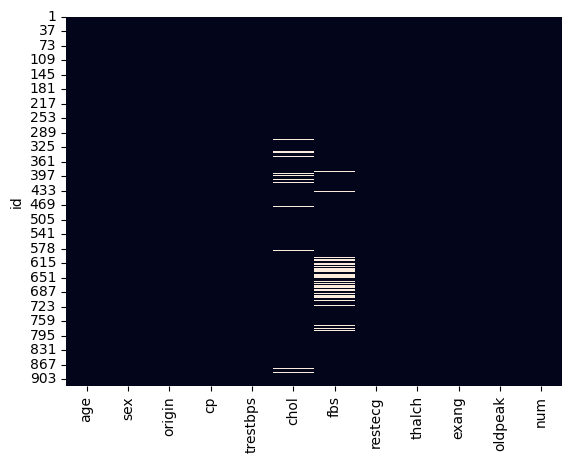

In [376]:
sns.heatmap(cardio_df.isna(), cbar=False)
plt.show()



Vemos que para esas 4 variables ya fueron imputadas su valores nulos por eso se ven completamente en negro

---
## **Ejercicio 7**

**Para las variables que aún presentan valores faltantes, realiza la imputación utilizando estadísticas generales calculadas sobre toda la columna, sin segmentar por grupos. Esta vez utiliza la clase `SimpleImputer` de sklearn.**

In [377]:
print(cardio_df.isna().sum()[lambda s: s > 0])

chol    30
fbs     89
dtype: int64


Vemos que solo falta imputar estas 2 variables: `chol` y `fbs`



In [378]:
# chol es numérica y muy sesgada entonces usamos MEDIANA
imp_mediana = SimpleImputer(strategy='median')
cardio_df['chol'] = imp_mediana.fit_transform(cardio_df[['chol']])

# fbs es categórica (True/False) entonces usamos MOST_FREQUENT
imp_moda = SimpleImputer(strategy='most_frequent')
fbs_imputada = imp_moda.fit_transform(cardio_df[['fbs']].astype(object))
cardio_df['fbs'] = pd.Categorical(fbs_imputada.ravel(), categories=[False, True])

print('Faltantes totales:', cardio_df.isna().sum().sum())

Faltantes totales: 0


Vemos que finalmente fueron imputadas

* **Justifica la estrategia (*mean, median, most_frequent*) que emplees en cada caso.**

Explayamos más lo que se puso arriba

| Variable | Estrategia | Valor | Justificación |
|---|---|---|---|
| chol | median | 223.0 | Es muy sesgada (+1.64) y llega hasta 603 mg/dl, la media se desplazaría hacia esos extremos por eso la mediana seria la mejor opcion ya que no es tan sensible a este desplazamiento por el sesgo |
| fbs | most_frequent | False | Es categórica asi que la media y la mediana no tienen sentido, solo queda la moda |

---
## **Ejercicio 8**

**Dibuja boxplots de todas las variables numéricas.**

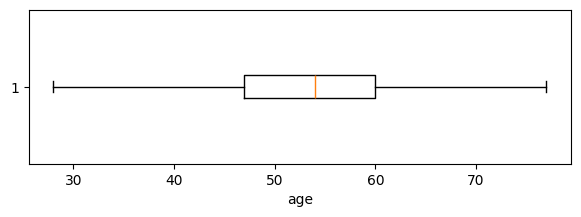

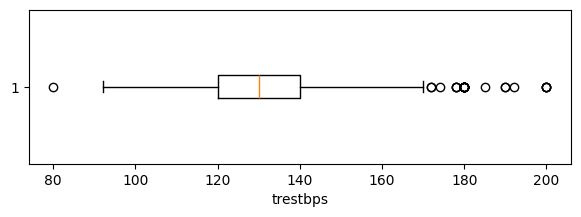

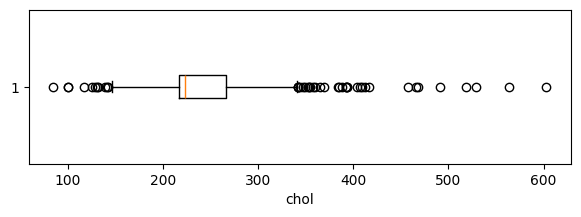

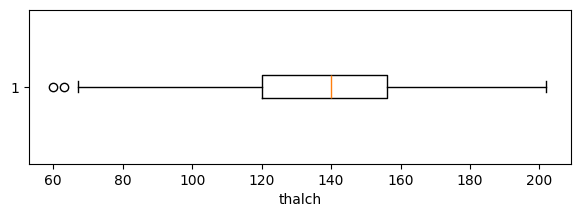

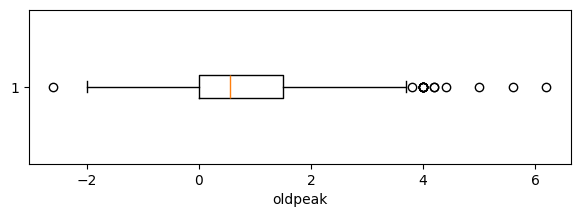

In [379]:
num_cols = cardio_df.select_dtypes(include='number').columns

boxplots = {}

for att in num_cols:
    plt.figure(figsize=(7, 2))
    boxplots[att] = plt.boxplot(cardio_df[att].dropna(), vert=False)
    plt.xlabel(att)
    plt.show()

* **Obtén los valores atípicos mediante el método gráfico, a partir del objeto devuelto por el boxplot.**

In [380]:
atipicos_grafico = {}

for att in num_cols:
    fliers = boxplots[att]['fliers'][0].get_data()[0]
    atipicos_grafico[att] = np.unique(fliers)
    #print('{}: {} atípicos -> {}'.format(att, len(fliers), atipicos_grafico[att]))
    print('la variable ',att,' tiene ',len(fliers),' atipicos, los cuales son: ',atipicos_grafico[att])
    print(" ")

la variable  age  tiene  0  atipicos, los cuales son:  []
 
la variable  trestbps  tiene  27  atipicos, los cuales son:  [ 80. 172. 174. 178. 180. 185. 190. 192. 200.]
 
la variable  chol  tiene  44  atipicos, los cuales son:  [ 85. 100. 117. 126. 129. 131. 132. 139. 141. 142. 342. 344. 347. 349.
 353. 354. 355. 358. 360. 365. 369. 384. 385. 388. 392. 393. 394. 404.
 407. 409. 412. 417. 458. 466. 468. 491. 518. 529. 564. 603.]
 
la variable  thalch  tiene  2  atipicos, los cuales son:  [60. 63.]
 
la variable  oldpeak  tiene  16  atipicos, los cuales son:  [-2.6  3.8  4.   4.2  4.4  5.   5.6  6.2]
 


la variable  `age`  tiene  0  atipicos, los cuales son:  []

la variable  `trestbps`  tiene  27  atipicos, los cuales son:  [ 80. 172. 174. 178. 180. 185. 190. 192. 200.]

la variable  `chol`  tiene  44  atipicos, los cuales son:  [ 85. 100. 117. 126. 129. 131. 132. 139. 141. 142. 342. 344. 347. 349.
 353. 354. 355. 358. 360. 365. 369. 384. 385. 388. 392. 393. 394. 404.
 407. 409. 412. 417. 458. 466. 468. 491. 518. 529. 564. 603.]

la variable  `thalch`  tiene  2  atipicos, los cuales son:  [60. 63.]

la variable  `oldpeak`  tiene  16  atipicos, los cuales son:  [-2.6  3.8  4.   4.2  4.4  5.   5.6  6.2]

---
## **Ejercicio 9**

**9. Para la variable `trestbps`, calcula los valores atípicos utilizando el método del rango intercuartílico (IQR).**

* **Para ello obtén los cuartiles necesarios y determina los límites superior e inferior para filtrar los valores que se encuentren fuera de ese rango.**

In [381]:
Q1 = cardio_df.trestbps.quantile(0.25)
Q3 = cardio_df.trestbps.quantile(0.75)
IQR = Q3 - Q1

print("Q1: ",Q1)
print("Q3: ",Q1)
print("IQR: ",Q1)
print(" ")

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print("limite_inferior: ",limite_inferior)
print("limite_superior: ",limite_superior)
print(" ")

BM_atipicos = (cardio_df.trestbps > limite_superior) | (cardio_df.trestbps < limite_inferior)
print('Registros atípicos:', BM_atipicos.sum())

Q1:  120.0
Q3:  120.0
IQR:  120.0
 
limite_inferior:  90.0
limite_superior:  170.0
 
Registros atípicos: 27


Q1:  120.0,
Q3:  120.0,
IQR:  120.0,

limite_inferior:  90.0,
limite_superior:  170.0

Registros atípicos: 27

* **Verifica si los resultados coinciden con los obtenidos en el ejercicio anterior.**

In [382]:
atipicos_iqr = np.unique(cardio_df.loc[BM_atipicos, 'trestbps'])

print('Método IQR:', atipicos_iqr)
print('Método gráfico:', atipicos_grafico['trestbps'])

print('Coincidencia', np.array_equal(atipicos_iqr, atipicos_grafico['trestbps']))


Método IQR: [ 80. 172. 174. 178. 180. 185. 190. 192. 200.]
Método gráfico: [ 80. 172. 174. 178. 180. 185. 190. 192. 200.]
Coincidencia True


Vemos que coinciden a simplevista y tambien usando el metodo `np.array_equal` que devuelve `True`

---
## **Ejercicio 10**



**10. Elimina los valores atípicos identificados de la variable `trestbps`.**

In [383]:
cardio_df = cardio_df[~BM_atipicos]

print('Registros eliminados:', BM_atipicos.sum())


Registros eliminados: 27


Se eliminaron 27 registros

* **Dibuja el boxplot final para visualizar la distribución depurada.**

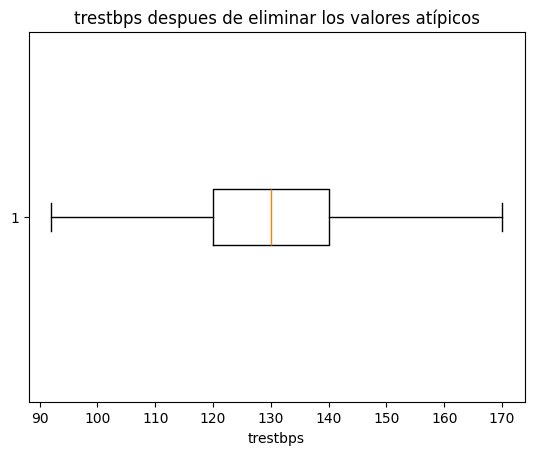

In [384]:
plt.boxplot(cardio_df.trestbps, vert=False)
plt.xlabel('trestbps')
plt.title('trestbps despues de eliminar los valores atípicos')
plt.show()

---

**Declaración de uso de IA**


Anthropic. (2026). *Claude (modelo Haiku)* [LLM], utilizado como corrector de formatos. https://claude.ai/

---